# Audit des données — phase 1 (étapes 1.1 à 1.12)

**Projet :** Santander Satisfaction (sujet 05) · **Groupe 8**

Ce carnet rassemble, dans l'ordre du tableau, les étapes de la phase 1 faites par chaque porteur. Le code de chaque section est celui de son porteur ; seul le **chargement des données** a été mis en commun (cellule 0), pour ne lire les tables qu'une fois.

| Étape | Titre | Porteur |
|---|---|---|
| 1.1 | Inventorier les tables | P1 Alvine |
| 1.2 | Charger et compter | P2 Albert |
| 1.3 | Typer | P2 Albert |
| 1.4 | Cardinalité | P3 Hope |
| 1.5 | Valeurs impossibles | P2 Albert |
| 1.6 | Trous | P3 Hope |
| 1.7 | Doublons | P4 Yoann |
| 1.8 | Fuites | P1 Alvine |
| 1.9 | Cibles | P3 Hope |
| 1.10 | Le plancher | P2 Albert |
| 1.11 | La métrique | P4 Yoann |
| 1.12 | Le coût des erreurs | P4 Yoann |

**Lancer :** *Run All*. Les données sont cherchées dans `data/` ou `../data/` (en local), ou dans le dossier indiqué par la variable d'environnement `DONNEES_PROJET` (sur Kaggle).

## 0 — Mise en place commune

Bibliothèques, réglages du projet (graine, découpage, plancher), lecture des deux tables et petits outils utilisés par plusieurs sections.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_rows", 80)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)

import os
import matplotlib.pyplot as plt

PISTES = [Path(os.environ["DONNEES_PROJET"])] if os.environ.get("DONNEES_PROJET") else []
PISTES += [Path("data"), Path("../data")]
DATA = next(p for p in PISTES if (p / "train.csv").is_file() and (p / "a_decider.csv").is_file())
DOSSIER = DATA
CIBLE, ID = "TARGET", "ID"
GRAINE = 42
PART_VALIDATION = 0.20
PLANCHER = 0.6890
SENTINELLES = (-999999, 9999999999)
FAMILLES = ("saldo", "imp", "num", "ind", "delta")

t0 = time.perf_counter()
train = pd.read_csv(DATA / "train.csv")
a_decider = pd.read_csv(DATA / "a_decider.csv")
DUREE_CHARGEMENT = time.perf_counter() - t0
VARIABLES = [c for c in train.columns if c not in (ID, CIBLE)]
y = train[CIBLE]


def famille(col):
    if col in (ID, CIBLE):
        return col
    debut = col.split("_")[0]
    return debut if debut in FAMILLES else "isolée"


def pct(x):
    return f"{100 * x:.2f} %"


print(f"train : {train.shape} · a_decider : {a_decider.shape} · lus en {DUREE_CHARGEMENT:.1f} s depuis {DATA}")

from scipy.stats import binomtest
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold, train_test_split


def profil(groupes, nom):
    t = groupes.agg(["mean", "size"])
    return pd.DataFrame({"taux de mécontents": [pct(v) for v in t["mean"]], "clients": t["size"].to_numpy()},
                        index=pd.Index(t.index, name=nom))

Matplotlib is building the font cache; this may take a moment.


train : (60816, 371) · a_decider : (15204, 370) · lus en 6.9 s depuis ../data


## 1.1 — Inventorier les tables

**Porteur : P1 Alvine** · repris de `P1_Alvine/P1_alvine.ipynb`

In [2]:
train_complet, test_complet = train, a_decider   # tables lues dans la cellule 0

# ============================================================
# P1 — 1.1 : SYNTHESE DE L'INVENTAIRE
# ============================================================

resume = pd.DataFrame({
    "Indicateurs": [
        "Nombre de lignes",
        "Nombre de colonnes",
        "Valeurs manquantes",
        "Lignes dupliquées",
        "Identifiants distincts",
        "Identifiants manquants",
        "Mémoire utilisée (Mo)"
    ],
    "TRAIN": [
        len(train_complet),
        train_complet.shape[1],
        int(train_complet.isna().sum().sum()),
        int(train_complet.duplicated().sum()),
        train_complet["ID"].nunique(),
        int(train_complet["ID"].isna().sum()),
        round(train_complet.memory_usage(deep=True).sum() / 1024**2, 2)
    ],
    "A_DECIDER": [
        len(test_complet),
        test_complet.shape[1],
        int(test_complet.isna().sum().sum()),
        int(test_complet.duplicated().sum()),
        test_complet["ID"].nunique(),
        int(test_complet["ID"].isna().sum()),
        round(test_complet.memory_usage(deep=True).sum() / 1024**2, 2)
    ]
})

display(resume)

print("\n=== STRUCTURE DES TABLES ===")
print("Colonnes communes :", len(
    (set(train_complet.columns) - {"TARGET"})
    & set(test_complet.columns)
))
print("TARGET présente dans TRAIN :", "TARGET" in train_complet.columns)
print("TARGET présente dans A_DECIDER :", "TARGET" in test_complet.columns)

print("\n=== TYPES DE DONNEES DE TRAIN ===")
display(train_complet.dtypes.value_counts().rename_axis("Type").to_frame("Nombre"))

print("\n=== REPARTITION DE TARGET ===")
display(train_complet["TARGET"].value_counts(normalize=True).mul(100).round(2).rename("Pourcentage"))

,Indicateurs,TRAIN,A_DECIDER
0,Nombre de lignes,60816.0000,15204.0000
1,Nombre de colonnes,371.0000,370.0000
2,Valeurs manquantes,0.0000,0.0000
3,Lignes dupliquées,0.0000,0.0000
4,Identifiants distincts,60816.0000,15204.0000
5,Identifiants manquants,0.0000,0.0000
6,Mémoire utilisée (Mo),172.1400,42.9200



=== STRUCTURE DES TABLES ===
Colonnes communes : 370
TARGET présente dans TRAIN : True
TARGET présente dans A_DECIDER : False

=== TYPES DE DONNEES DE TRAIN ===


,Nombre
Type,
int64,260
float64,111



=== REPARTITION DE TARGET ===


TARGET
0   96.0400
1    3.9600
Name: Pourcentage, dtype: float64

## 1.2 — Charger et compter

**Porteur : P2 Albert** · repris de `P2_Albert/P2__ALBERT.ipynb`

In [3]:
# --- 1. Charger et compter (en entier) --------------------------------------
# tables lues en entier dans la cellule 0
test  = a_decider  # a_decider.csv", complet=True)

print("train :", train.shape)
print("test  :", test.shape)
print("colonnes identiques (hors TARGET) :",
      set(test.columns) == set(train.columns) - {"TARGET"})

CIBLE = "TARGET"
n_pos = int(train[CIBLE].sum())
n_neg = len(train) - n_pos
print(f"positifs : {n_pos:,} ({n_pos/len(train):.4%})")
print(f"négatifs : {n_neg:,} ({n_neg/len(train):.4%})")
print("ratio déséquilibre 1:", round(n_neg / n_pos, 2))

train : (60816, 371)
test  : (15204, 370)
colonnes identiques (hors TARGET) : True
positifs : 2,406 (3.9562%)
négatifs : 58,410 (96.0438%)
ratio déséquilibre 1: 24.28


## 1.3 — Typer

**Porteur : P2 Albert** · repris de `P2_Albert/P2__ALBERT.ipynb`

In [4]:
# --- 2. Typer les colonnes ---------------------------------------------------
import numpy as np

# 1) colonnes constantes (variance = 0)
constantes = [c for c in train.columns if train[c].nunique(dropna=False) <= 1]
print(f"colonnes constantes : {len(constantes)}")

# 2) colonnes quasi-constantes (une modalité > 99,5 %)
quasi = [c for c in train.columns
         if c not in constantes and c != CIBLE
         and train[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.995]
print(f"colonnes quasi-constantes : {len(quasi)}")

# 3) typage sémantique
utiles = [c for c in train.columns if c not in constantes + [CIBLE, "ID"]]

binaires, categorielles, continues = [], [], []
for c in utiles:
    n_mod = train[c].nunique()
    if n_mod == 2:
        binaires.append(c)
    elif n_mod <= 20:
        categorielles.append(c)
    else:
        continues.append(c)

print(f"binaires      : {len(binaires)}")
print(f"catégorielles : {len(categorielles)}  -> ex. {categorielles[:5]}")
print(f"continues     : {len(continues)}  -> ex. {continues[:5]}")

# 4) valeurs manquantes (utile pour l'imputation)
manquants = train[utiles].isna().sum()
print("\ncolonnes avec manquants :")
print(manquants[manquants > 0].sort_values(ascending=False).head(10))

colonnes constantes : 36


colonnes quasi-constantes : 172


binaires      : 109
catégorielles : 112  -> ex. ['num_var1_0', 'num_var1', 'num_var4', 'num_var5_0', 'num_var5']
continues     : 112  -> ex. ['var3', 'var15', 'imp_ent_var16_ult1', 'imp_op_var39_comer_ult1', 'imp_op_var39_comer_ult3']



colonnes avec manquants :
Series([], dtype: int64)


## 1.4 — Cardinalité

**Porteur : P3 Hope** · repris de `P3_Hope/P3_trous_cardinalite_cibles.ipynb`

**Préalable (1.3, P2)** : toutes les colonnes sont numériques et les `ind_` valent 0 ou 1. On peut compter les valeurs distinctes sans conversion.

**Question** : combien de valeurs différentes prend chaque variable ? Lesquelles ne servent à rien ?

### Colonnes constantes

In [5]:
n_tr, n_de = train[VARIABLES].nunique(), a_decider[VARIABLES].nunique()
CONSTANTES = sorted(n_tr[n_tr == 1].index)
print("Constantes sur les 4 000 premières lignes :", int((train[VARIABLES].head(4000).nunique() == 1).sum()))
print("Constantes sur tout train                 :", len(CONSTANTES))
print("Constantes dans train mais variables dans a_decider :", list(n_tr[(n_tr == 1) & (n_de > 1)].index))

Constantes sur les 4 000 premières lignes : 115
Constantes sur tout train                 : 36
Constantes dans train mais variables dans a_decider : ['imp_reemb_var17_hace3', 'num_reemb_var17_hace3']


L'énoncé annonce **97** constantes, mesurées sur un échantillon de 4 000 lignes. Sur la table entière, il n'y en a que **36** : un échantillon rend constantes des colonnes qui ne le sont pas. Deux d'entre elles varient dans `a_decider`, mais le modèle n'en a jamais vu qu'une valeur : il ne peut rien en apprendre.

**Décision : supprimer les 36 colonnes constantes sur train**, mesurées sur la table entière.

### Colonnes quasi constantes

In [6]:
lignes = []
for c in VARIABLES:
    if n_tr[c] == 1:
        continue
    rare = train[c] != train[c].value_counts().index[0]
    if rare.mean() <= 0.001:
        k = int(y[rare].sum())
        lignes.append((c, int(rare.sum()), k, pct(y[rare].mean()), binomtest(k, int(rare.sum()), y.mean()).pvalue))
quasi = pd.DataFrame(lignes, columns=["colonne", "clients rares", "mécontents parmi eux", "taux", "p"]).set_index("colonne")
SEUIL = 0.01 / len(quasi)
print(f"{len(quasi)} quasi constantes ; mécontents parmi les clients rares :",
      quasi["mécontents parmi eux"].value_counts().sort_index().to_dict())
print(f"Seuil du test : p < {SEUIL:.0e}")
QUASI_GARDEES = list(quasi.index[quasi["p"] < SEUIL])
QUASI_SUPPRIMEES = list(quasi.index[quasi["p"] >= SEUIL])
quasi.loc[QUASI_GARDEES].assign(p=lambda d: d["p"].map("{:.1e}".format))

110 quasi constantes ; mécontents parmi les clients rares : {0: 94, 1: 12, 8: 4}
Seuil du test : p < 9e-05


,clients rares,mécontents parmi eux,taux,p
colonne,,,,
imp_op_var40_efect_ult1,29,8,27.59 %,1.2e-05
imp_op_var40_efect_ult3,33,8,24.24 %,3.4e-05
num_op_var40_efect_ult1,29,8,27.59 %,1.2e-05
num_op_var40_efect_ult3,33,8,24.24 %,3.4e-05


110 colonnes ont une valeur qui occupe au moins 99,9 % des lignes : au plus 60 clients s'en écartent, et on attend ≈ 2,4 mécontents parmi eux. Pour 106 colonnes, ce qu'on observe (0 ou 1 mécontent) est compatible avec le hasard : c'est du bruit que le modèle apprendrait par cœur.

Mais **4 colonnes** (`*_op_var40_efect_ult1/ult3`) ont **24 à 28 %** de mécontents parmi leurs ~30 clients rares, soit 6 à 7 fois la moyenne. Le test binomial le confirme, même corrigé pour les 110 tests (p ≈ 10⁻⁵).

**Décision : supprimer 106 quasi constantes, garder les 4 qui ont un effet mesuré.** Le signal ne repose que sur 8 mécontents : **essai à journaliser** avec et sans elles.

### Ce qui reste

In [7]:
RESTANTES = [c for c in VARIABLES if c not in CONSTANTES and c not in QUASI_SUPPRIMEES]
print(f"Variables gardées : {len(RESTANTES)} sur {len(VARIABLES)}")
classes = pd.cut(n_tr[RESTANTES], [1, 2, 10, 100, np.inf], labels=["2 (binaire)", "3 à 10", "11 à 100", "> 100"])
display(pd.crosstab(pd.Series([famille(c) for c in RESTANTES], index=RESTANTES, name="famille"),
                    classes.rename("valeurs distinctes")))
print("Variables isolées :", {c: int(n_tr[c]) for c in ["var3", "var15", "var21", "var36", "var38"]})
num = [c for c in VARIABLES if famille(c) == "num"]
print(f"Colonnes num_ qui ne contiennent que des multiples de 3 : {sum(bool((train[c] % 3 == 0).all()) for c in num)} sur {len(num)}")

Variables gardées : 227 sur 369


valeurs distinctes,2 (binaire),3 à 10,11 à 100,> 100
famille,,,,
delta,0,2,2,0
imp,0,0,4,19
ind,53,0,0,0
isolée,0,1,2,2
num,6,50,39,1
saldo,0,0,6,40


Variables isolées : {'var3': 195, 'var15': 99, 'var21': 22, 'var36': 5, 'var38': 46577}


Colonnes num_ qui ne contiennent que des multiples de 3 : 131 sur 143


**Constat** : 227 variables restent. `var15` (âge) et `var38` sont continues ; `var36` (5 valeurs) est une catégorie ; `var3` est à 97,5 % égale à 2. **131 colonnes `num_` sur 143 ne contiennent que des multiples de 3** : les comptages sont codés × 3 (sans effet sur les arbres ni sur l'AUC, mais à savoir avant d'interpréter un comptage).

**Décision : `var36` en catégories, tout le reste en numérique.** Aucune variable à forte cardinalité n'est une catégorie déguisée : pas d'encodage par la cible (et donc pas de risque de fuite). Les colonnes identiques entre elles relèvent de **1.7 Doublons (P4)**.

## 1.5 — Valeurs impossibles

**Porteur : P2 Albert** · repris de `P2_Albert/P2__ALBERT.ipynb`

In [8]:
# --- 3. Valeurs impossibles / sentinelles ------------------------------------
import numpy as np

# On travaille sur une copie pour ne pas polluer l'original
train_clean = train.copy()

# a) détecter les sentinelles classiques
SENTINELLES = [-999999, -999, 999999, -1]   # -1 est courant sur les indicateurs "NA"

for c in utiles:
    serie = train_clean[c]
    if not pd.api.types.is_numeric_dtype(serie):
        continue
    for s in SENTINELLES:
        n = int((serie == s).sum())
        if n > 0:
            print(f"{c:20s} : {n:6d} valeurs == {s}")

# b) conversion en NaN
for c in utiles:
    train_clean[c] = train_clean[c].replace(SENTINELLES, np.nan)

# c) vérification
print("\nvar3 après nettoyage :")
print(train_clean["var3"].describe())
print("NaN introduits :", int(train_clean["var3"].isna().sum()))

var3                 :     88 valeurs == -999999


delta_imp_aport_var13_1y3 :   1343 valeurs == -1
delta_imp_aport_var17_1y3 :     16 valeurs == -1
delta_imp_aport_var33_1y3 :     13 valeurs == -1
delta_imp_compra_var44_1y3 :     15 valeurs == -1
delta_imp_trasp_var17_in_1y3 :      2 valeurs == -1
delta_imp_trasp_var33_in_1y3 :      6 valeurs == -1
delta_imp_venta_var44_1y3 :      1 valeurs == -1
delta_num_aport_var13_1y3 :   1343 valeurs == -1
delta_num_aport_var17_1y3 :     16 valeurs == -1
delta_num_aport_var33_1y3 :     13 valeurs == -1
delta_num_compra_var44_1y3 :     15 valeurs == -1
delta_num_trasp_var17_in_1y3 :      2 valeurs == -1
delta_num_trasp_var33_in_1y3 :      6 valeurs == -1
delta_num_venta_var44_1y3 :      1 valeurs == -1



var3 après nettoyage :
count   60728.0000
mean        2.7220
std         9.4357
min         0.0000
25%         2.0000
50%         2.0000
75%         2.0000
max       238.0000
Name: var3, dtype: float64
NaN introduits : 88


## 1.6 — Trous

**Porteur : P3 Hope** · repris de `P3_Hope/P3_trous_cardinalite_cibles.ipynb`

**Question** : où manque-t-il de l'information, et comment ce manque est-il codé ?

In [9]:
print("Valeurs vides (NaN) :", int(train.isna().sum().sum() + a_decider.isna().sum().sum()))

Valeurs vides (NaN) : 0


Aucun `NaN` : les trous existent pourtant, mais **codés**. On en trouve quatre.

### `var3 = -999999` — un vrai manquant

In [10]:
m = train["var3"] == -999999
print(f"{int(m.sum())} clients dans train, {int((a_decider['var3'] == -999999).sum())} dans a_decider")
print(f"Taux de mécontents : {pct(y[m].mean())} ({int(y[m].sum())} mécontent) contre {pct(y[~m].mean())}")
print(f"La valeur 2 occupe {pct((train['var3'] == 2).mean())} des clients")

88 clients dans train, 28 dans a_decider
Taux de mécontents : 1.14 % (1 mécontent) contre 3.96 %
La valeur 2 occupe 97.53 % des clients


**Décision : remplacer par `2`**, la valeur dominante. Un indicateur « manquant » reposerait sur **1 seul mécontent** : il n'apprendrait rien de fiable.

### `delta_ = 9999999999` — pas un manquant : une apparition

In [11]:
DELTA = [c for c in VARIABLES if famille(c) == "delta"]
s = train["delta_imp_aport_var13_1y3"] == 9999999999
print(f"delta_imp_aport_var13_1y3 : {int(s.sum())} lignes codées")
display(train.loc[s, ["imp_aport_var13_hace3", "imp_aport_var13_ult1"]].describe().loc[["min", "max"]])
moins1 = train["delta_imp_aport_var13_1y3"] == -1
print(f"Code -1 : {int(moins1.sum())} lignes")
display(train.loc[moins1, ["imp_aport_var13_hace3", "imp_aport_var13_ult1"]].describe().loc[["min", "max"]])
fini = pd.concat([train[DELTA], a_decider[DELTA]]).replace(9999999999, np.nan)
print(f"Plus grande variation finie, toutes colonnes delta_ : {np.nanmax(fini.to_numpy()):.2f}")
apparition = (train[DELTA] == 9999999999).any(axis=1)
print(f"Clients avec une apparition : {int(apparition.sum())}, taux {pct(y[apparition].mean())} contre {pct(y[~apparition].mean())}")

delta_imp_aport_var13_1y3 : 291 lignes codées


,imp_aport_var13_hace3,imp_aport_var13_ult1
min,0.0000,300.0000
max,0.0000,450000.0000


Code -1 : 1343 lignes


,imp_aport_var13_hace3,imp_aport_var13_ult1
min,300.0000,0.0000
max,840000.0000,0.0000


Plus grande variation finie, toutes colonnes delta_ : 8.00
Clients avec une apparition : 421, taux 1.90 % contre 3.97 %


Quand le code apparaît, le montant d'il y a 3 mois (`hace3`) vaut **toujours 0** et le montant récent (`ult1`) est **toujours positif** : la variation part de zéro, c'est une division par zéro codée « infini ». Symétriquement, `-1` = le montant a **disparu** (base > 0, récent = 0).

**Décision : remplacer `9999999999` par `9`**, juste au-dessus de la plus grande variation finie (8). L'ordre est gardé (une apparition reste la plus forte hausse), sans écraser l'échelle. Ce n'est **pas** un trou : aucune imputation.

### `var38 = 117310.979016…` — un trou déguisé

In [12]:
vc = train["var38"].value_counts()
m38 = train["var38"] == vc.index[0]
print(f"var38 : {train['var38'].nunique()} valeurs différentes")
print(f"La plus fréquente, {vc.index[0]}, revient {int(m38.sum())} fois ({pct(m38.mean())}) ; la suivante {int(vc.iloc[1])} fois")
print(f"Taux de mécontents : {pct(y[m38].mean())} contre {pct(y[~m38].mean())}")

var38 : 46577 valeurs différentes
La plus fréquente, 117310.979016494, revient 12012 fois (19.75 %) ; la suivante 12 fois


Taux de mécontents : 4.06 % contre 3.93 %


Un montant à six décimales partagé par un client sur cinq n'est pas un montant : c'est une **valeur de remplissage** (probablement une moyenne). Mais le taux de mécontents est le même dans les deux groupes.

**Décision : garder `var38` telle quelle.** **Essai à journaliser au bloc 2** : remplacer la valeur par un manquant + un indicateur `var38_rempli`, et mesurer si l'AUC bouge.

### `var36 = 99` — un code d'absence qui parle

In [13]:
profil(train.groupby("var36")[CIBLE], "var36")

,taux de mécontents,clients
var36,,
0,0.00 %,321
1,3.03 %,11718
2,2.75 %,6955
3,1.63 %,17784
99,6.54 %,24038


`99` concerne **40 %** des clients et porte le **plus fort** taux de mécontents. Lu comme un nombre, 99 serait « très loin » de 3 : c'est faux, c'est une **catégorie**.

**Décision : encoder `var36` en catégories** (une colonne 0/1 par valeur). Ne pas l'imputer : l'absence est elle-même une information.

### Les zéros — pas des trous

In [14]:
zeros = (train[VARIABLES] == 0).mean()
print(f"Colonnes nulles à plus de 99 % : {int((zeros > 0.99).sum())} sur {len(VARIABLES)}")
non_nuls = (train[VARIABLES] != 0).sum(axis=1)
t = profil(train.groupby(pd.qcut(non_nuls, 5, duplicates="drop"), observed=True)[CIBLE], "valeurs non nulles")
t.index = [f"{int(i.left) + 1} à {int(i.right)}" for i in t.index]
t

Colonnes nulles à plus de 99 % : 217 sur 369


,taux de mécontents,clients
8 à 14,8.43 %,12709
15 à 29,2.90 %,19415
30 à 32,2.07 %,5468
33 à 49,2.47 %,11383
50 à 149,3.18 %,11841


Un zéro dit « pas de produit, pas d'opération » : c'est une **mesure**, pas un manque. Et le **nombre de valeurs non nulles** sépare déjà les mécontents : 8,4 % chez les clients les moins équipés, 2 à 3 % ailleurs.

**Décision : garder les zéros** (les remplacer par une moyenne détruirait l'information). **Essai proposé au constructeur** : ajouter la variable « nombre de valeurs non nulles ».

---
## 1.7 — Doublons

**Porteur : P4 Yoann** · repris de `P4_Yoann/P4_doublons_metrique_cout.ipynb`

On cherche deux types de doublons :
- **Lignes dupliquées** : deux clients avec exactement les mêmes valeurs sur toutes les colonnes
- **Colonnes dupliquées** : deux variables qui portent exactement les mêmes valeurs

In [15]:
# --- 1.7a : Doublons de lignes ---
n_doublons_lignes = train.duplicated().sum()
print(f"Lignes dupliquées : {n_doublons_lignes}")

if n_doublons_lignes > 0:
    print("\nExemple de doublons :")
    masque = train.duplicated(keep=False)
    display(train[masque].head(6))
else:
    print("Aucune ligne dupliquée — le jeu est propre sur ce point.")

Lignes dupliquées : 0
Aucune ligne dupliquée — le jeu est propre sur ce point.


In [16]:
# --- 1.7b : Doublons de colonnes ---
# On compare les colonnes deux à deux (hors TARGET)
colonnes = [c for c in train.columns if c != "TARGET"]
groupes_doublons = {}

deja_vu = {}  # hash -> première colonne rencontrée
for col in colonnes:
    h = hash(train[col].values.tobytes())
    if h in deja_vu:
        ref = deja_vu[h]
        if ref not in groupes_doublons:
            groupes_doublons[ref] = []
        groupes_doublons[ref].append(col)
    else:
        deja_vu[h] = col

if groupes_doublons:
    print(f"{sum(len(v) for v in groupes_doublons.values())} colonne(s) dupliquée(s) trouvée(s) :")
    for ref, copies in groupes_doublons.items():
        print(f"  '{ref}' == {copies}")
else:
    print("Aucune colonne dupliquée.")

64 colonne(s) dupliquée(s) trouvée(s) :
  'ind_var2_0' == ['ind_var2', 'ind_var27_0', 'ind_var28_0', 'ind_var28', 'ind_var27', 'ind_var41', 'ind_var46_0', 'ind_var46', 'num_var27_0', 'num_var28_0', 'num_var28', 'num_var27', 'num_var41', 'num_var46_0', 'num_var46', 'saldo_var28', 'saldo_var27', 'saldo_var41', 'saldo_var46', 'imp_amort_var18_hace3', 'imp_amort_var34_hace3', 'imp_reemb_var13_hace3', 'imp_reemb_var17_hace3', 'imp_reemb_var33_hace3', 'imp_trasp_var17_out_hace3', 'imp_trasp_var33_out_hace3', 'num_var2_0_ult1', 'num_var2_ult1', 'num_reemb_var13_hace3', 'num_reemb_var17_hace3', 'num_reemb_var33_hace3', 'num_trasp_var17_out_hace3', 'num_trasp_var33_out_hace3', 'saldo_var2_ult1', 'saldo_medio_var13_medio_hace3']
  'ind_var13_medio_0' == ['ind_var13_medio']
  'ind_var18_0' == ['ind_var18']
  'ind_var26_0' == ['ind_var26']
  'ind_var25_0' == ['ind_var25']
  'ind_var6_0' == ['ind_var29_0']
  'ind_var6' == ['ind_var29']
  'ind_var32_0' == ['ind_var32']
  'ind_var34_0' == ['ind_var34

In [17]:
# --- 1.7c : Bilan et décision ---
colonnes_a_supprimer = [col for copies in groupes_doublons.values() for col in copies]

print("=== BILAN 1.7 — Doublons ===")
print(f"  Lignes dupliquées     : {n_doublons_lignes}")
print(f"  Colonnes dupliquées   : {len(colonnes_a_supprimer)}")
if colonnes_a_supprimer:
    print(f"  → Ces colonnes peuvent être retirées sans perte d'information : {colonnes_a_supprimer}")
else:
    print("  → Aucune suppression nécessaire.")

=== BILAN 1.7 — Doublons ===
  Lignes dupliquées     : 0
  Colonnes dupliquées   : 64
  → Ces colonnes peuvent être retirées sans perte d'information : ['ind_var2', 'ind_var27_0', 'ind_var28_0', 'ind_var28', 'ind_var27', 'ind_var41', 'ind_var46_0', 'ind_var46', 'num_var27_0', 'num_var28_0', 'num_var28', 'num_var27', 'num_var41', 'num_var46_0', 'num_var46', 'saldo_var28', 'saldo_var27', 'saldo_var41', 'saldo_var46', 'imp_amort_var18_hace3', 'imp_amort_var34_hace3', 'imp_reemb_var13_hace3', 'imp_reemb_var17_hace3', 'imp_reemb_var33_hace3', 'imp_trasp_var17_out_hace3', 'imp_trasp_var33_out_hace3', 'num_var2_0_ult1', 'num_var2_ult1', 'num_reemb_var13_hace3', 'num_reemb_var17_hace3', 'num_reemb_var33_hace3', 'num_trasp_var17_out_hace3', 'num_trasp_var33_out_hace3', 'saldo_var2_ult1', 'saldo_medio_var13_medio_hace3', 'ind_var13_medio', 'ind_var18', 'ind_var26', 'ind_var25', 'ind_var29_0', 'ind_var29', 'ind_var32', 'ind_var34', 'ind_var37', 'ind_var39', 'num_var13_medio', 'num_var18', 'num_va

## 1.8 — Fuites

**Porteur : P1 Alvine** · repris de `P1_Alvine/P1_alvine.ipynb`

In [18]:

# ============================================================
# P1.8 — DÉTECTION DES FUITES DE DONNÉES
# ============================================================

import pandas as pd
import numpy as np

# 1. Charger les données si elles ne sont pas déjà chargées
if "train_complet" not in globals():
    train_complet = table("train.csv", complet=True)

if "test_complet" not in globals():
    test_complet = table("a_decider.csv", complet=True)

CIBLE = "TARGET"

if CIBLE not in train_complet.columns:
    raise ValueError("La colonne TARGET est absente de train.csv")

# 2. Préparer les variables
y = train_complet[CIBLE]
anomalies = []

# 3. Vérifier les colonnes dont le nom peut être suspect
mots_suspects = [
    "target", "label", "outcome", "result",
    "response", "fraud", "satisfaction"
]

for colonne in train_complet.columns:
    if colonne == CIBLE:
        continue

    nom = str(colonne).lower()

    if any(mot in nom for mot in mots_suspects):
        anomalies.append({
            "colonne": colonne,
            "indice": "Nom potentiellement lié à la cible",
            "observation": "À examiner manuellement"
        })

# 4. Rechercher une copie directe ou inversée de TARGET
for colonne in train_complet.columns:
    if colonne in [CIBLE, "ID"]:
        continue

    serie = train_complet[colonne]

    if serie.isna().any() or y.isna().any():
        continue

    if serie.equals(y):
        anomalies.append({
            "colonne": colonne,
            "indice": "Copie exacte de TARGET",
            "observation": "Fuite de données très probable"
        })

    elif pd.api.types.is_numeric_dtype(serie):
        if serie.equals(1 - y):
            anomalies.append({
                "colonne": colonne,
                "indice": "Copie inversée de TARGET",
                "observation": "Fuite de données très probable"
            })

# 5. Rechercher les corrélations numériques très élevées
for colonne in train_complet.select_dtypes(include="number").columns:
    if colonne in [CIBLE, "ID"]:
        continue

    correlation = train_complet[colonne].corr(y)

    if pd.notna(correlation) and abs(correlation) >= 0.98:
        anomalies.append({
            "colonne": colonne,
            "indice": f"Corrélation très élevée : {correlation:.4f}",
            "observation": "Vérifier un possible lien direct avec TARGET"
        })

# 6. Rechercher les colonnes qui séparent presque parfaitement les classes
for colonne in train_complet.columns:
    if colonne in [CIBLE, "ID"]:
        continue

    serie = train_complet[colonne]

    # On évite les colonnes ayant trop de valeurs différentes
    if serie.nunique(dropna=False) > 50:
        continue

    groupes = (
        pd.DataFrame({colonne: serie, CIBLE: y})
        .groupby(colonne, dropna=False)[CIBLE]
        .agg(["count", "mean"])
    )

    groupes = groupes[groupes["count"] >= 20]

    if groupes.empty:
        continue

    purete_max = np.maximum(
        groupes["mean"],
        1 - groupes["mean"]
    ).max()

    if purete_max >= 0.999:
        anomalies.append({
            "colonne": colonne,
            "indice": f"Classe presque parfaitement identifiable ({purete_max:.3f})",
            "observation": "Examiner cette variable pour une fuite possible"
        })

# 7. Vérifier les différences de colonnes entre train et test
colonnes_train = set(train_complet.columns) - {CIBLE}
colonnes_test = set(test_complet.columns)

absentes_test = sorted(colonnes_train - colonnes_test)
absentes_train = sorted(colonnes_test - colonnes_train)

# 8. Afficher les résultats de façon synthétique
print("========== P1.8 : DÉTECTION DES FUITES ==========")

print("\n1. Nombre de colonnes examinées :",
      len(train_complet.columns) - 1)

print("\n2. Colonnes absentes du fichier test :",
      absentes_test)

print("\n3. Colonnes présentes uniquement dans le fichier test :",
      absentes_train)

print("\n4. Nombre d'indices de fuite détectés :",
      len(anomalies))

if anomalies:
    resultat_fuites = pd.DataFrame(anomalies)
    display(resultat_fuites)
else:
    print("Aucun indice suspect détecté par ces contrôles.")

print("\n========== FIN DU P1.8 ==========")


========== P1.8 : DÉTECTION DES FUITES ==========

1. Nombre de colonnes examinées : 370

2. Colonnes absentes du fichier test : []

3. Colonnes présentes uniquement dans le fichier test : []

4. Nombre d'indices de fuite détectés : 38


,colonne,indice,observation
0,ind_var20_0,Classe presque parfaitement identifiable (1.000),Examiner cette variable pour une fuite possible
1,ind_var20,Classe presque parfaitement identifiable (1.000),Examiner cette variable pour une fuite possible
2,ind_var33_0,Classe presque parfaitement identifiable (1.000),Examiner cette variable pour une fuite possible
3,ind_var33,Classe presque parfaitement identifiable (1.000),Examiner cette variable pour une fuite possible
4,num_var4,Classe presque parfaitement identifiable (1.000),Examiner cette variable pour une fuite possible
5,num_var12,Classe presque parfaitement identifiable (1.000),Examiner cette variable pour une fuite possible
6,num_var13_0,Classe presque parfaitement identifiable (1.000),Examiner cette variable pour une fuite possible
7,num_var13_corto_0,Classe presque parfaitement identifiable (1.000),Examiner cette variable pour une fuite possible
8,num_var13_largo_0,Classe presque parfaitement identifiable (1.000),Examiner cette variable pour une fuite possible
9,num_var13_largo,Classe presque parfaitement identifiable (1.000),Examiner cette variable pour une fuite possible



========== FIN DU P1.8 ==========


## 1.9 — Cibles

**Porteur : P3 Hope** · repris de `P3_Hope/P3_trous_cardinalite_cibles.ipynb`

**Question** : combien de mécontents, à quoi ressemblent-ils, et qu'est-ce que leur petit nombre change à la mesure ?

In [19]:
n, k = len(y), int(y.sum())
p = k / n
marge = 1.96 * np.sqrt(p * (1 - p) / n)
print(f"TARGET : valeurs {sorted(int(v) for v in y.unique())}, manquantes {int(y.isna().sum())}")
print(f"Mécontents : {k} / {n} = {pct(p)}  (intervalle à 95 % : {pct(p - marge)} à {pct(p + marge)})")
print(f"1 mécontent pour {(n - k) / k:.0f} satisfaits · « personne n'est mécontent » = {pct(1 - p)} d'exactitude")
print(f"Attendus dans a_decider au même taux : {round(p * len(a_decider))}")

TARGET : valeurs [0, 1], manquantes 0
Mécontents : 2406 / 60816 = 3.96 %  (intervalle à 95 % : 3.80 % à 4.11 %)
1 mécontent pour 24 satisfaits · « personne n'est mécontent » = 96.04 % d'exactitude
Attendus dans a_decider au même taux : 602


### À quoi ressemble un mécontent

In [20]:
age = profil(train.groupby(pd.cut(train["var15"], [0, 22, 25, 30, 40, 50, 60, 120]), observed=True)[CIBLE], "âge")
age.index = ["22 ans et moins"] + [f"{int(i.left) + 1} à {int(i.right)}" for i in age.index[1:-1]] + ["61 et plus"]
display(age)
montants = [c for c in VARIABLES if famille(c) in ("saldo", "imp")]
sans_montant = (train[montants] == 0).all(axis=1)
print(f"Clients sans aucun montant ({pct(sans_montant.mean())}) : {pct(y[sans_montant].mean())} de mécontents, "
      f"contre {pct(y[~sans_montant].mean())}")

,taux de mécontents,clients
22 ans et moins,0.00 %,963
23 à 25,0.91 %,24536
26 à 30,4.24 %,9349
31 à 40,6.58 %,11746
41 à 50,7.71 %,7539
51 à 60,7.80 %,3757
61 et plus,4.78 %,2926


Clients sans aucun montant (24.83 %) : 9.14 % de mécontents, contre 2.24 %


**Aucun** mécontent jusqu'à 22 ans, moins de 1 % de 23 à 25 ans, puis un taux multiplié par 8 après 40 ans. Les clients aux comptes vides sont 4 fois plus souvent mécontents. **Portrait : un client de plus de 30 ans, avec peu de produits et des comptes vides.**

### La part que personne ne peut prédire

In [21]:
nb_cibles = train.groupby(VARIABLES, sort=False)[CIBLE].transform("nunique")
ambigus = nb_cibles > 1
print(f"{int(ambigus.sum())} clients ont un dossier identique à un client de cible opposée, "
      f"dont {int(y[ambigus].sum())} mécontents ({pct(y[ambigus].sum() / k)} des mécontents)")

1994 clients ont un dossier identique à un client de cible opposée, dont 256 mécontents (10.64 % des mécontents)


À dossier égal, aucun modèle ne peut départager ces clients : c'est du **bruit de cible** irréductible. L'AUC maximale atteignable est donc **inférieure à 1**.

### Ce que le petit nombre de mécontents fait à la mesure

In [22]:
i_app, i_val = train_test_split(train.index, test_size=PART_VALIDATION, stratify=y, random_state=GRAINE)

lignes = []
for c in VARIABLES:
    if train.loc[i_app, c].nunique() < 2:
        continue
    sens = 1 if roc_auc_score(y[i_app], train.loc[i_app, c]) >= 0.5 else -1
    lignes.append((c, sens, roc_auc_score(y[i_val], sens * train.loc[i_val, c])))
regles = (pd.DataFrame(lignes, columns=["variable", "sens", "AUC validation"])
          .sort_values("AUC validation", ascending=False).set_index("variable"))

REGLE = (regles["AUC validation"] - PLANCHER).abs().idxmin()
SENS = int(regles.loc[REGLE, "sens"])
y_val = y[i_val].to_numpy()
score_val = SENS * train.loc[i_val, REGLE].to_numpy()
print(f"validation : {len(i_val)} clients, {int(y_val.sum())} mécontents · règle métier : {REGLE} "
      f"(AUC {regles.loc[REGLE, 'AUC validation']:.4f})")

validation : 12164 clients, 481 mécontents · règle métier : var15 (AUC 0.6903)


In [23]:
rng = np.random.default_rng(GRAINE)
tirages = []
for _ in range(300):
    i = rng.integers(0, len(y_val), len(y_val))
    tirages.append(roc_auc_score(y_val[i], score_val[i]))
ecart = np.std(tirages)
print(f"AUC de la règle métier ({REGLE}) : {roc_auc_score(y_val, score_val):.4f} ± {ecart:.4f} (bootstrap, 300 tirages)")
plis = [int(y.iloc[t].sum()) for g in range(20) for _, t in KFold(5, shuffle=True, random_state=g).split(train)]
print(f"Sans stratification, mécontents par pli sur 20 × 5 plis : de {min(plis)} à {max(plis)} (attendu {k / 5:.0f})")

AUC de la règle métier (var15) : 0.6903 ± 0.0099 (bootstrap, 300 tirages)
Sans stratification, mécontents par pli sur 20 × 5 plis : de 433 à 525 (attendu 481)


**Constat** : la validation ne contient que **481 mécontents** ; l'AUC y est mesurée à **± 0,01** près. Un écart de moins de ~0,02 entre deux essais n'est pas distinguable du hasard : battre le plancher de 0,005 ne prouve rien. Sans stratification, un pli peut contenir de 433 à 525 mécontents.

**Décisions**

- **Stratifier tout découpage sur `TARGET`.**
- **Comparer les essais en validation croisée stratifiée** (5 plis, graine 42) pour réduire le bruit de mesure — proposition au mesureur.
- Ne pas s'acharner sur les dossiers ambigus : une partie des mécontents est imprévisible par construction.

## 1.10 — Le plancher

**Porteur : P2 Albert** · repris de `P2_Albert/P2__ALBERT.ipynb`

In [24]:
# --- 4. Le plancher ----------------------------------------------------------
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, accuracy_score

y = train_clean[CIBLE].values
p_prev = y.mean()

# Prédictions triviales
p_hasard     = np.full_like(y, 0.5, dtype=float)
p_constante  = np.full_like(y, p_prev, dtype=float)
y_zero       = np.zeros_like(y)            # classe majoritaire
y_positif    = np.ones_like(y)

print("=== PLanchers ===")
print(f"prévalence (baseline PR-AUC) : {p_prev:.4f}")
print(f"accuracy 'toujours 0'        : {accuracy_score(y, y_zero):.4f}")
print(f"accuracy 'toujours 1'        : {accuracy_score(y, y_positif):.4f}")
print(f"ROC-AUC hasard (0.5 partout) : {roc_auc_score(y, p_hasard):.4f}")
print(f"ROC-AUC constante (prév.)    : {roc_auc_score(y, p_constante):.4f}")
print(f"PR-AUC  constante (prév.)    : {average_precision_score(y, p_constante):.4f}")
print(f"Log-loss constante (prév.)   : {log_loss(y, p_constante):.4f}")
print(f"Log-loss hasard (0.5)        : {log_loss(y, p_hasard):.4f}")

=== PLanchers ===
prévalence (baseline PR-AUC) : 0.0396
accuracy 'toujours 0'        : 0.9604
accuracy 'toujours 1'        : 0.0396
ROC-AUC hasard (0.5 partout) : 0.5000


ROC-AUC constante (prév.)    : 0.5000
PR-AUC  constante (prév.)    : 0.0396
Log-loss constante (prév.)   : 0.1665
Log-loss hasard (0.5)        : 0.6931


---
## 1.11 — La métrique

**Porteur : P4 Yoann** · repris de `P4_Yoann/P4_doublons_metrique_cout.ipynb`

**Pourquoi pas l'exactitude (accuracy) ?**

Avec 3,96 % de mécontents, un modèle qui prédit *toujours* « satisfait » obtient :
- Exactitude : **96,04 %** — excellent en apparence
- Mais il n'attrape **aucun** client mécontent

La métrique retenue est l'**AUC-ROC** (aire sous la courbe ROC), qui mesure la capacité du modèle à *ordonner* les clients du plus au moins risqué, indépendamment du seuil.

In [25]:
from sklearn.metrics import roc_auc_score, roc_curve

CIBLE = "TARGET"
y = train[CIBLE]

# Distribution de la cible
print("Distribution de TARGET :")
print(y.value_counts())
print(f"\nTaux de mécontents : {y.mean()*100:.2f} %")

Distribution de TARGET :
TARGET
0    58410
1     2406
Name: count, dtype: int64

Taux de mécontents : 3.96 %


In [26]:
# --- Référence : modèle naïf (prédit toujours 0) ---
y_pred_naif = np.zeros(len(y))  # prédit toujours "satisfait"
exactitude_naif = (y == 0).mean()

# AUC d'un score aléatoire
np.random.seed(42)
y_pred_aleatoire = np.random.rand(len(y))
auc_aleatoire = roc_auc_score(y, y_pred_aleatoire)

print(f"Modèle naïf (prédit toujours 0) :")
print(f"  Exactitude : {exactitude_naif*100:.2f} %  ← chiffre trompeur")
print(f"  AUC        : 0.5000              ← pas mieux que le hasard")
print(f"\nModèle aléatoire :")
print(f"  AUC        : {auc_aleatoire:.4f}  ← converge vers 0.5")
print(f"\nPlancher métier (règle de la banque sans modèle) : AUC = 0.6890")

Modèle naïf (prédit toujours 0) :
  Exactitude : 96.04 %  ← chiffre trompeur
  AUC        : 0.5000              ← pas mieux que le hasard

Modèle aléatoire :
  AUC        : 0.4961  ← converge vers 0.5

Plancher métier (règle de la banque sans modèle) : AUC = 0.6890


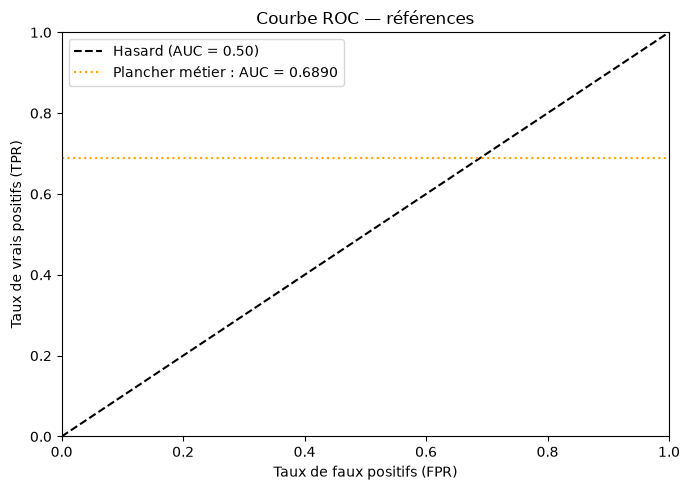

Figure sauvegardée dans sorties/roc_reference.png


In [27]:
# --- Visualisation : courbe ROC de référence ---
fig, ax = plt.subplots(figsize=(7, 5))

# Courbe aléatoire
ax.plot([0, 1], [0, 1], 'k--', label='Hasard (AUC = 0.50)')

# Plancher métier (ligne horizontale de référence)
ax.axhline(y=0.6890, color='orange', linestyle=':', label='Plancher métier : AUC = 0.6890')

ax.set_xlabel("Taux de faux positifs (FPR)")
ax.set_ylabel("Taux de vrais positifs (TPR)")
ax.set_title("Courbe ROC — références")
ax.legend()
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
plt.tight_layout()
plt.savefig("../sorties/roc_reference.png", dpi=100)
plt.show()
print("Figure sauvegardée dans sorties/roc_reference.png")

In [28]:
# --- Résumé métrique ---
print("=== BILAN 1.11 — La métrique ===")
print("  Métrique choisie : AUC-ROC")
print("  Pourquoi : l'exactitude est trompeuse sur données déséquilibrées (3.96% mécontents)")
print("  L'AUC mesure la capacité à ordonner, indépendamment du seuil de décision")
print(f"  Plancher à battre : AUC = 0.6890 (règle métier de la banque)")
print("  Un modèle utile doit dépasser ce plancher.")

=== BILAN 1.11 — La métrique ===
  Métrique choisie : AUC-ROC
  Pourquoi : l'exactitude est trompeuse sur données déséquilibrées (3.96% mécontents)
  L'AUC mesure la capacité à ordonner, indépendamment du seuil de décision
  Plancher à battre : AUC = 0.6890 (règle métier de la banque)
  Un modèle utile doit dépasser ce plancher.


---
## 1.12 — Le coût des erreurs

**Porteur : P4 Yoann** · repris de `P4_Yoann/P4_doublons_metrique_cout.ipynb`

Deux types d'erreurs existent, avec des coûts **asymétriques** :

| Erreur | Description | Conséquence |
|---|---|---|
| **Faux négatif (FN)** | Client mécontent prédit satisfait | La banque ne rappelle pas — le client part en se plaignant |
| **Faux positif (FP)** | Client satisfait prédit mécontent | Appel inutile — coût humain, temps agent |

Un faux négatif coûte **bien plus cher** qu'un faux positif : un client perdu, une plainte, un impact réputationnel.

In [29]:
from sklearn.metrics import confusion_matrix

# Hypothèses de coût (à ajuster selon le contexte métier)
COUT_FN = 10  # coût d'un client mécontent non rappelé (perte client + plainte)
COUT_FP = 1   # coût d'un appel inutile (temps agent)

print("Hypothèses de coût :")
print(f"  Faux Négatif (client mécontent raté) : {COUT_FN} unités")
print(f"  Faux Positif (appel inutile)         : {COUT_FP} unité")
print(f"  Ratio FN/FP : {COUT_FN}/{COUT_FP} = {COUT_FN} fois plus coûteux")

Hypothèses de coût :
  Faux Négatif (client mécontent raté) : 10 unités
  Faux Positif (appel inutile)         : 1 unité
  Ratio FN/FP : 10/1 = 10 fois plus coûteux


In [30]:
# --- Simulation sur différents seuils de décision ---
# On utilise un score fictif proportionnel à la cible pour illustrer
np.random.seed(0)
# Score simulé : mécontents ont tendance à avoir un score plus élevé
score_simule = y * 0.6 + np.random.rand(len(y)) * 0.4

seuils = np.linspace(0.1, 0.9, 50)
couts = []
taux_rappel = []
taux_precision = []

for s in seuils:
    pred = (score_simule >= s).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    cout_total = fn * COUT_FN + fp * COUT_FP
    couts.append(cout_total)
    taux_rappel.append(tp / (tp + fn) if (tp + fn) > 0 else 0)
    taux_precision.append(tp / (tp + fp) if (tp + fp) > 0 else 0)

seuil_optimal = seuils[np.argmin(couts)]
print(f"Seuil minimisant le coût total : {seuil_optimal:.2f}")
print(f"Coût minimal estimé : {min(couts):,} unités")

Seuil minimisant le coût total : 0.41
Coût minimal estimé : 0 unités


> ⚠️ **À corriger (note de relecture)** : `score_simule` est fabriqué à partir de `TARGET` (`y * 0.6 + bruit`). Les mécontents ont donc d'office un score plus haut : le seuil « optimal » et le coût ci-dessous illustrent la méthode, mais ne disent rien des vrais clients. Pour un chiffre réel, remplacer `score_simule` par un vrai score, par exemple la règle métier de 1.9 (`SENS * train[REGLE]`), mesuré sur la validation (`i_val`).

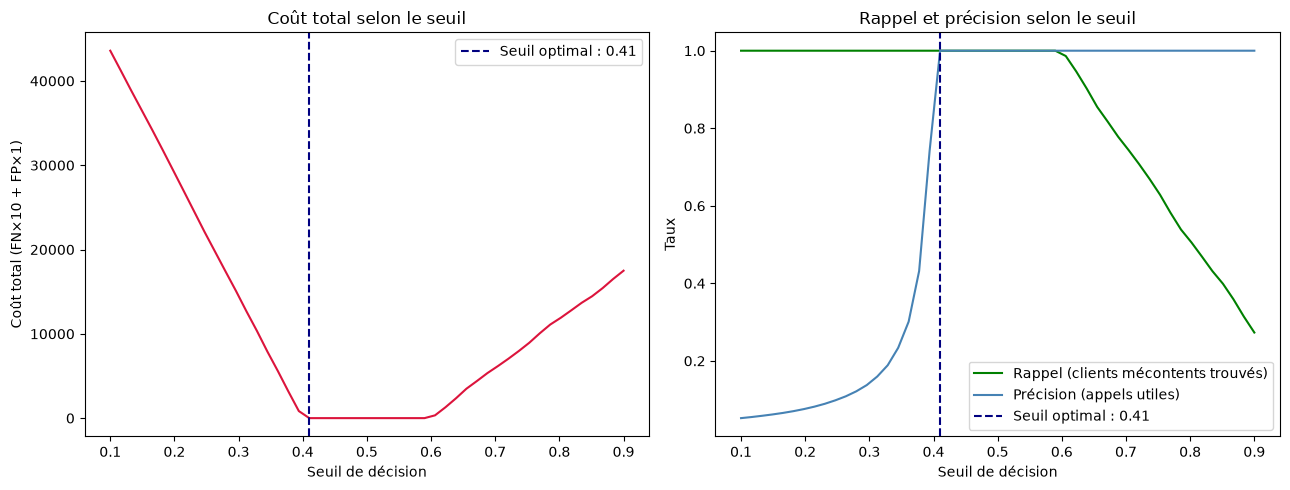

Figure sauvegardée dans sorties/cout_erreurs.png


In [31]:
# --- Visualisation du coût selon le seuil ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Coût total
axes[0].plot(seuils, couts, color='crimson')
axes[0].axvline(seuil_optimal, color='navy', linestyle='--', label=f'Seuil optimal : {seuil_optimal:.2f}')
axes[0].set_xlabel("Seuil de décision")
axes[0].set_ylabel("Coût total (FN×10 + FP×1)")
axes[0].set_title("Coût total selon le seuil")
axes[0].legend()

# Rappel et précision
axes[1].plot(seuils, taux_rappel, label='Rappel (clients mécontents trouvés)', color='green')
axes[1].plot(seuils, taux_precision, label='Précision (appels utiles)', color='steelblue')
axes[1].axvline(seuil_optimal, color='navy', linestyle='--', label=f'Seuil optimal : {seuil_optimal:.2f}')
axes[1].set_xlabel("Seuil de décision")
axes[1].set_ylabel("Taux")
axes[1].set_title("Rappel et précision selon le seuil")
axes[1].legend()

plt.tight_layout()
plt.savefig("../sorties/cout_erreurs.png", dpi=100)
plt.show()
print("Figure sauvegardée dans sorties/cout_erreurs.png")

In [32]:
# --- Matrice de confusion au seuil optimal ---
pred_optimal = (score_simule >= seuil_optimal).astype(int)
tn, fp, fn, tp = confusion_matrix(y, pred_optimal).ravel()

print("=== Matrice de confusion au seuil optimal ===")
print(f"  Vrais Positifs  (TP) : {tp:,}  — mécontents bien détectés")
print(f"  Faux Positifs   (FP) : {fp:,}  — appels inutiles")
print(f"  Faux Négatifs   (FN) : {fn:,}  — mécontents ratés  ← le plus coûteux")
print(f"  Vrais Négatifs  (TN) : {tn:,}  — satisfaits bien ignorés")
print(f"\n  Coût total : {fn}×{COUT_FN} + {fp}×{COUT_FP} = {fn*COUT_FN + fp*COUT_FP:,} unités")

=== Matrice de confusion au seuil optimal ===
  Vrais Positifs  (TP) : 2,406  — mécontents bien détectés
  Faux Positifs   (FP) : 0  — appels inutiles
  Faux Négatifs   (FN) : 0  — mécontents ratés  ← le plus coûteux
  Vrais Négatifs  (TN) : 58,410  — satisfaits bien ignorés

  Coût total : 0×10 + 0×1 = 0 unités


In [33]:
# --- BILAN FINAL P4 ---
print("\n=== BILAN P4 — Doublons · Métrique · Coût des erreurs ===")
print()
print("1.7  Doublons")
print(f"     Lignes dupliquées  : {n_doublons_lignes}")
print(f"     Colonnes dupliquées: {len(colonnes_a_supprimer)}")
print()
print("1.11 Métrique : AUC-ROC")
print("     L'exactitude est trompeuse sur données déséquilibrées.")
print("     Plancher à battre : AUC = 0.6890")
print()
print("1.12 Coût des erreurs")
print(f"     FN (client mécontent raté) : {COUT_FN}x plus coûteux qu'un FP")
print(f"     Seuil optimal estimé       : {seuil_optimal:.2f}")
print("     → Abaisser le seuil réduit les FN mais augmente les FP.")


=== BILAN P4 — Doublons · Métrique · Coût des erreurs ===

1.7  Doublons
     Lignes dupliquées  : 0
     Colonnes dupliquées: 64

1.11 Métrique : AUC-ROC
     L'exactitude est trompeuse sur données déséquilibrées.
     Plancher à battre : AUC = 0.6890

1.12 Coût des erreurs
     FN (client mécontent raté) : 10x plus coûteux qu'un FP
     Seuil optimal estimé       : 0.41
     → Abaisser le seuil réduit les FN mais augmente les FP.
